# Week 2: Cleaning the data

This notebook does four things, in order:

1. **Load** the 12 CSV files.
2. **Clean** them, and write down every change.
3. **Check** the cleaned data.
4. **Build** one table with one row per product and branch, which we use in later weeks.

Run each cell from top to bottom, using **Runtime → Run all**.

## Step 1: Set up
This creates the folders we need. In Colab, it also asks you to upload the 12 CSV files.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = Path("data/raw")          # the 12 CSV files go here
OUT = Path("data/cleaned")      # cleaned files are saved here
DOCS = Path("docs")             # logs and notes are saved here
for folder in (RAW, OUT, DOCS):
    folder.mkdir(parents=True, exist_ok=True)

# In Colab, upload the files if none are there yet
if "google.colab" in sys.modules and not any(RAW.glob("*.csv")):
    from google.colab import files
    for name, content in files.upload().items():
        (RAW / name).write_bytes(content)

print("CSV files found:", len(list(RAW.glob("*.csv"))), "of 12")

Saving branches.csv to branches (1).csv
Saving customers.csv to customers (1).csv
Saving inventory_master.csv to inventory_master (1).csv
Saving invoices.csv to invoices (1).csv
Saving payments.csv to payments (1).csv
Saving products.csv to products (1).csv
Saving purchase_orders_header.csv to purchase_orders_header (1).csv
Saving purchase_orders_lines.csv to purchase_orders_lines (1).csv
Saving sales_orders_header.csv to sales_orders_header (1).csv
Saving sales_orders_lines.csv to sales_orders_lines (1).csv
Saving stock_ledger.csv to stock_ledger (1).csv
Saving suppliers.csv to suppliers (1).csv
CSV files found: 12 of 12


## Step 2: Load the files

We keep an untouched copy of each file in `raw`, and do all cleaning on a second copy.

In [3]:
import shutil

file_names = {
    "branches": "branches.csv",
    "customers": "customers.csv",
    "products": "products.csv",
    "suppliers": "suppliers.csv",
    "sales_orders": "sales_orders_header.csv",
    "sales_lines": "sales_orders_lines.csv",
    "purchase_orders": "purchase_orders_header.csv",
    "purchase_lines": "purchase_orders_lines.csv",
    "invoices": "invoices.csv",
    "payments": "payments.csv",
    "inventory": "inventory_master.csv",
    "stock_ledger": "stock_ledger.csv",
}

# Ensure files are in RAW. If they are in the root directory (even with ' (1)' suffix), copy them over.
for name, file in file_names.items():
    target_path = RAW / file
    if not target_path.exists():
        # Check root directory with suffix first, then without
        stem = Path(file).stem
        suffix = Path(file).suffix
        possible_sources = [
            Path(f"{stem} (1){suffix}"),
            Path(file)
        ]
        for src in possible_sources:
            if src.exists():
                shutil.copy(src, target_path)
                break

raw = {name: pd.read_csv(RAW / file) for name, file in file_names.items()}
data = {name: df.copy() for name, df in raw.items()}   # we clean these copies

for name, df in raw.items():
    print(f"{name:16s} {len(df):>10,} rows")

branches                  6 rows
customers               500 rows
products                 30 rows
suppliers                 8 rows
sales_orders         20,000 rows
sales_lines         130,402 rows
purchase_orders      24,000 rows
purchase_lines      155,495 rows
invoices             18,033 rows
payments             19,257 rows
inventory               180 rows
stock_ledger        237,230 rows


## Step 3: Find the blank cells

Blank cells are missing values. For each one, we decide what to do with it.
Here, the only column with blanks is `received_date`, which is blank for pending purchase orders.
We **leave these blank**. We do not guess a date.

In [4]:
blanks = []
for name, df in raw.items():
    for column in df.columns:
        count = df[column].isna().sum()
        if count > 0:
            blanks.append((name, column, count))

for name, column, count in blanks:
    print(f"{name}.{column}: {count:,} blank cells")

# Stop if a new blank column appears that we have not reviewed
reviewed = {("purchase_orders", "received_date")}
new_blanks = [(t, c) for t, c, _ in blanks if (t, c) not in reviewed]
assert not new_blanks, f"Decide what to do with these blanks: {new_blanks}"

purchase_orders.received_date: 2,370 blank cells


## Step 4: Clean the data

Each change is written to a list called `cleaning_log`, so anyone can see what was changed and how many rows it affected.

In [5]:
cleaning_log = []

# 4a. Remove extra spaces from text
spaces_fixed = 0
for name, df in data.items():
    for column in df.select_dtypes(include=["object", "string"]).columns:
        before = df[column]
        after = before.str.strip()
        spaces_fixed += int((before.notna() & (before != after)).sum())
        df[column] = after
cleaning_log.append({"table": "all", "change": "removed extra spaces from text", "rows": spaces_fixed})

# 4b. Turn text dates into real dates. Dates that cannot be read become blank.
date_columns = {
    "customers": ["customer_since", "last_purchase_date"],
    "products": ["last_purchase_date"],
    "sales_orders": ["order_date", "delivery_date"],
    "purchase_orders": ["order_date", "expected_delivery_date", "received_date"],
    "invoices": ["invoice_date", "due_date"],
    "payments": ["payment_date"],
    "stock_ledger": ["movement_date"],
}
for name, columns in date_columns.items():
    for column in columns:
        converted = pd.to_datetime(data[name][column], errors="coerce")
        bad = data[name][column].notna() & converted.isna()
        data[name][column] = converted
        if bad.sum() > 0:
            cleaning_log.append({"table": name, "change": f"unreadable date in {column}", "rows": int(bad.sum())})

# 4c. Branch capacity is text like "45230 sqft". Split the number and the unit.
capacity_text = data["branches"]["warehouse_capacity"].astype("string").str.strip()
data["branches"]["warehouse_capacity_unit"] = capacity_text.str.extract(r"([A-Za-z]+)\s*$")[0]
data["branches"]["warehouse_capacity"] = pd.to_numeric(
    capacity_text.str.extract(r"^([\d.,]+)")[0].str.replace(",", ""), errors="coerce")
cleaning_log.append({"table": "branches", "change": "split capacity into number and unit", "rows": len(capacity_text)})

# 4d. Flag invoice IDs that are used by more than one invoice. We keep them, but flag them.
invoices = data["invoices"]
id_counts = invoices["invoice_id"].value_counts()
invoices["shared_invoice_id"] = invoices["invoice_id"].map(id_counts) > 1
cleaning_log.append({"table": "invoices", "change": "invoice_id used by more than one invoice (flagged, kept)",
                     "rows": int(invoices["shared_invoice_id"].sum())})

# 4e. Flag payment IDs that are used by more than one payment. We keep them, but flag them.
payments = data["payments"]
payments["shared_payment_id"] = payments["payment_id"].duplicated(keep=False)
cleaning_log.append({"table": "payments", "change": "payment_id used by more than one payment (flagged, kept)",
                     "rows": int(payments["shared_payment_id"].sum())})

# 4f. Purchase orders: a PO is pending if it has no received date. Keep it blank.
purchase_orders = data["purchase_orders"]
purchase_orders["is_received"] = purchase_orders["received_date"].notna()
cleaning_log.append({"table": "purchase_orders", "change": "pending POs (no received date), kept blank",
                     "rows": int((~purchase_orders["is_received"]).sum())})

# 4g. Stock movements: ADJUSTMENT rows have no direction (IN or OUT) in the source.
ledger = data["stock_ledger"]
adjustments = int((ledger["movement_type"] == "ADJUSTMENT").sum())
cleaning_log.append({"table": "stock_ledger", "change": "ADJUSTMENT rows with no direction (excluded from stock check)",
                     "rows": adjustments})

log_table = pd.DataFrame(cleaning_log)
log_table.to_csv(DOCS / "cleaning_log.csv", index=False)
log_table

,table,change,rows
0,all,removed extra spaces from text,0
1,branches,split capacity into number and unit,6
2,invoices,invoice_id used by more than one invoice (flag...,393
3,payments,payment_id used by more than one payment (flag...,403
4,purchase_orders,"pending POs (no received date), kept blank",2370
5,stock_ledger,ADJUSTMENT rows with no direction (excluded fr...,2454


## Step 5: Check the cleaned data

Each check prints PASS or FAIL. If any check fails, the notebook stops, so we do not build on bad data.

In [6]:
results = []

def check(description, passed):
    results.append({"check": description, "result": "PASS" if passed else "FAIL"})

# Cleaning must not lose rows
for name in raw:
    check(f"no rows lost: {name}", len(raw[name]) == len(data[name]))

# Product, branch, order and invoice IDs must be unique
check("products: product_id unique", data["products"]["product_id"].is_unique)
check("branches: branch_id unique", data["branches"]["branch_id"].is_unique)
check("sales orders: so_id unique", data["sales_orders"]["so_id"].is_unique)
check("customers: customer_id unique", data["customers"]["customer_id"].is_unique)
check("inventory: product and branch pair unique",
      not data["inventory"].duplicated(["product_id", "branch_id"]).any())

# Every link between tables must point to a row that exists
links = [
    ("sales_lines", "so_id", "sales_orders", "so_id"),
    ("sales_lines", "product_id", "products", "product_id"),
    ("sales_orders", "customer_id", "customers", "customer_id"),
    ("purchase_lines", "po_id", "purchase_orders", "po_id"),
    ("purchase_orders", "supplier_id", "suppliers", "supplier_id"),
    ("inventory", "product_id", "products", "product_id"),
    ("stock_ledger", "product_id", "products", "product_id"),
]
for child, child_col, parent, parent_col in links:
    missing = ~data[child][child_col].dropna().isin(data[parent][parent_col])
    check(f"no missing links: {child}.{child_col} -> {parent}", missing.sum() == 0)

# Revenue must agree between the order header and its lines
header_total = data["sales_orders"]["total_order_value"].sum()
line_total = data["sales_lines"]["line_total"].sum()
check("order header total matches line total", abs(header_total - line_total) < 1)

checks = pd.DataFrame(results)
checks.to_csv(DOCS / "validation_checks.csv", index=False)
print(f"{(checks['result'] == 'PASS').sum()} of {len(checks)} checks passed")
assert (checks["result"] == "PASS").all(), "Some checks failed. See docs/validation_checks.csv"
checks

25 of 25 checks passed


,check,result
0,no rows lost: branches,PASS
1,no rows lost: customers,PASS
2,no rows lost: products,PASS
3,no rows lost: suppliers,PASS
4,no rows lost: sales_orders,PASS
5,no rows lost: sales_lines,PASS
6,no rows lost: purchase_orders,PASS
7,no rows lost: purchase_lines,PASS
8,no rows lost: invoices,PASS
9,no rows lost: payments,PASS


## Step 6: Build the measures

We calculate three things for each product:

- **Monthly sales:** units sold each month. We leave out Cancelled and Returned orders.
- **Days of stock:** how many days the current stock would last at the recent sales rate.
- **Lead time:** how many days it takes from ordering to receiving a product.

In [7]:
# Sales: join each line to its order, so we know the branch and the date
sales = (data["sales_lines"]
         .merge(data["sales_orders"][["so_id", "branch_id", "order_date", "order_status"]], on="so_id"))
sales = sales[~sales["order_status"].isin(["Cancelled", "Returned"])]
sales["month"] = sales["order_date"].dt.to_period("M").dt.to_timestamp()

# Monthly sales per product and branch
monthly_sales = sales.groupby(["product_id", "branch_id", "month"], as_index=False).agg(
    units=("quantity", "sum"), revenue=("line_total", "sum"))
monthly_sales.to_csv(OUT / "monthly_sales.csv", index=False)

# Average units per month over the last 12 months
last_month = sales["month"].max()
start_month = last_month - pd.DateOffset(months=11)
recent = monthly_sales[monthly_sales["month"] >= start_month]
avg_monthly_units = (recent.groupby(["product_id", "branch_id"])["units"].sum() / 12).rename("avg_monthly_units")

# Demand per day: stock moved OUT in the last 90 days, divided by 90
ledger = data["stock_ledger"]
latest_date = ledger["movement_date"].max()
recent_out = ledger[(ledger["movement_type"] == "OUT") &
                    (ledger["movement_date"] > latest_date - pd.Timedelta(days=90))]
daily_out = (recent_out.groupby(["product_id", "branch_id"])["quantity"].sum() / 90).rename("avg_daily_out")

# Lead time: days from ordering to receiving, only for received POs
lines = data["purchase_lines"].merge(
    data["purchase_orders"][["po_id", "order_date", "received_date", "is_received"]], on="po_id")
received = lines[lines["is_received"]].copy()
received["lead_days"] = (received["received_date"] - received["order_date"]).dt.days
lead_time = received.groupby("product_id")["lead_days"].mean().rename("actual_lead_days")

print("Monthly sales rows:", len(monthly_sales))
print("Latest month in the data:", last_month.strftime("%B %Y"))
print("Latest ledger date:", latest_date.strftime("%d %B %Y"))

Monthly sales rows: 12955
Latest month in the data: December 2024
Latest ledger date: 28 January 2025


## Step 7: Build the product-branch table

One row for each product in each branch (180 rows). We add the measures from Step 6, plus some flags.

In [8]:
table = data["inventory"][["product_id", "branch_id", "opening_stock", "current_stock", "reorder_level"]].copy()

table = table.merge(data["products"][["product_id", "product_name", "category", "unit_cost", "lead_time_days"]],
                    on="product_id", how="left")
table = table.merge(data["branches"][["branch_id", "region"]], on="branch_id", how="left")
table = table.merge(avg_monthly_units, on=["product_id", "branch_id"], how="left")
table = table.merge(daily_out, on=["product_id", "branch_id"], how="left")
table = table.merge(lead_time, on="product_id", how="left")

table["avg_monthly_units"] = table["avg_monthly_units"].fillna(0)
table["avg_daily_out"] = table["avg_daily_out"].fillna(0)
table["days_of_stock"] = table["current_stock"] / table["avg_daily_out"].replace(0, np.nan)
table["stock_value"] = table["current_stock"] * table["unit_cost"]
table["is_stockout"] = table["current_stock"] <= 0
table["needs_reorder"] = table["current_stock"] <= table["reorder_level"]
table["lead_time_gap_days"] = table["actual_lead_days"] - table["lead_time_days"]

assert len(table) == len(data["inventory"]), "The table should have one row per product-branch"
print("Rows:", len(table), "| Columns:", table.shape[1])
table.head()

Rows: 180 | Columns: 18


,product_id,branch_id,opening_stock,current_stock,reorder_level,product_name,category,unit_cost,lead_time_days,region,avg_monthly_units,avg_daily_out,actual_lead_days,days_of_stock,stock_value,is_stockout,needs_reorder,lead_time_gap_days
0,P001,DEL001,196,115928,59,Hydraulic Pump HP-300,Hydraulic,18950,21,North,84.583333,1.888889,17.707228,61373.647059,2196835600,False,False,-3.292772
1,P001,PUN001,198,109389,70,Hydraulic Pump HP-300,Hydraulic,18950,21,West,97.083333,2.800000,17.707228,39067.500000,2072921550,False,False,-3.292772
2,P001,CHN001,187,99373,62,Hydraulic Pump HP-300,Hydraulic,18950,21,South,104.333333,1.888889,17.707228,52609.235294,1883118350,False,False,-3.292772
3,P001,HYD001,226,108772,71,Hydraulic Pump HP-300,Hydraulic,18950,21,South,72.666667,2.522222,17.707228,43125.462555,2061229400,False,False,-3.292772
4,P001,KOL001,263,103808,94,Hydraulic Pump HP-300,Hydraulic,18950,21,East,114.666667,1.955556,17.707228,53083.636364,1967161600,False,False,-3.292772


## Step 8: Check the stock numbers, then save

The stock numbers are checked against demand. If current stock is much larger than demand, the stock unit may be wrong.
We write this warning into `open_flags.csv`, so it is not missed.

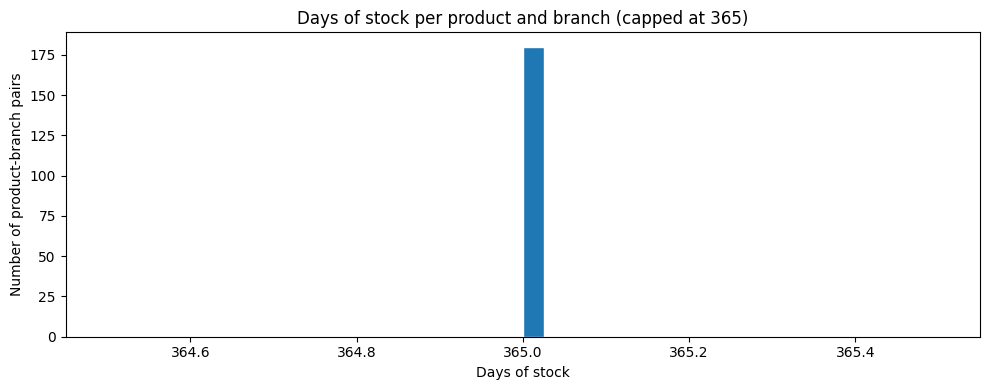

Median days of stock: 52,625
Open flag saved. The stock numbers should not be used yet.


In [9]:
median_days = table["days_of_stock"].median()
stock_in_months = (table["current_stock"] / table["avg_monthly_units"].replace(0, np.nan)).median()

flags = []
if median_days > 365:
    flags.append({
        "flag": "Stock looks too large compared with demand",
        "detail": f"Median days of stock is {median_days:,.0f}. Current stock is about {stock_in_months:,.0f} months of demand.",
        "what_to_do": "Ask CadetX what unit stock is measured in. Do not use days of stock, reorder or stockout flags until this is answered.",
    })
flag_table = pd.DataFrame(flags)
flag_table.to_csv(DOCS / "open_flags.csv", index=False)

# Chart: days of stock (capped at 365 so the chart is readable)
plt.figure(figsize=(10, 4))
plt.hist(table["days_of_stock"].dropna().clip(upper=365), bins=40, edgecolor="white")
plt.title("Days of stock per product and branch (capped at 365)")
plt.xlabel("Days of stock")
plt.ylabel("Number of product-branch pairs")
plt.tight_layout()
plt.show()

print(f"Median days of stock: {median_days:,.0f}")
if len(flags):
    print("Open flag saved. The stock numbers should not be used yet.")

## Step 9: Save the results

These files are used in Week 3 and later weeks.

In [10]:
table.to_csv(OUT / "analytical_dataset.csv", index=False)
for name, df in data.items():
    df.to_csv(OUT / f"{name}_clean.csv", index=False)

print("Saved:")
for path in sorted(OUT.glob("*.csv")):
    print("  ", path)
print("  ", DOCS / "cleaning_log.csv")
print("  ", DOCS / "validation_checks.csv")
print("  ", DOCS / "open_flags.csv")

Saved:
   data/cleaned/analytical_dataset.csv
   data/cleaned/branches_clean.csv
   data/cleaned/customers_clean.csv
   data/cleaned/inventory_clean.csv
   data/cleaned/invoices_clean.csv
   data/cleaned/monthly_sales.csv
   data/cleaned/payments_clean.csv
   data/cleaned/products_clean.csv
   data/cleaned/purchase_lines_clean.csv
   data/cleaned/purchase_orders_clean.csv
   data/cleaned/sales_lines_clean.csv
   data/cleaned/sales_orders_clean.csv
   data/cleaned/stock_ledger_clean.csv
   data/cleaned/suppliers_clean.csv
   docs/cleaning_log.csv
   docs/validation_checks.csv
   docs/open_flags.csv


In [11]:
import shutil
from google.colab import files

shutil.make_archive("week02_docs", "zip", ".", "docs")
files.download("week02_docs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
%history -f week02_code.py
from google.colab import files
files.download("week02_code.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>